<a href="https://colab.research.google.com/github/sayedHoosini/AI_Portfolio_ITAI2372/blob/main/Module_05_Lab_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  THIS WORK WAS ONLY FOR PRACTICE PRUPOSE EVERY CODE CELL HERE DID NOT FOLLOW THE ASSIGNMENT INSTRUCTION PLEASE MAKE THE CHANGE AS YOU WISH. ::
# Module 05 Lab - Data Preparation**Objective:** To learn and apply the most common data preparation techniques. Raw data is rarely ready for a machine learning model. This process, also called preprocessing, is one of the most critical steps in the entire ML workflow.**In this lab, you will write more of the code.** Read the explanations and then complete the tasks in the code cells.

## Part 1: Setup and Initial LookWe will continue using the Titanic dataset because it has the exact problems we need to solve: missing values and non-numeric data.

In [ ]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')

# Let's look at the missing values
print("--- Missing Values Before Cleaning ---")
print(df.isnull().sum())

--- Missing Values Before Cleaning ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

# Load the Titanic dataset directly from seaborn's built-in library
df = sns.load_dataset('titanic')

# Display the first 5 rows
print("--- FIRST 5 ROWS ---")
display(df.head())

print("\n--- DATASET SUMMARY & MISSING VALUES ---")
df.info()


--- FIRST 5 ROWS ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



--- DATASET SUMMARY & MISSING VALUES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


## Part 2: Handling Missing Values (Imputation)**Concept:** Most machine learning models cannot handle missing values (`NaN`). We must deal with them. Dropping the rows is an option, but you lose data. A better way is **imputation**, which means filling in the missing values with a calculated guess.Common imputation strategies:*   **Mean:** Fill with the average value. Good for normally distributed data.*   **Median:** Fill with the middle value. Better for skewed data or data with outliers (like `Fare`).*   **Mode:** Fill with the most frequent value. Used for categorical data.

### Task 1: Impute the 'Age' ColumnThe 'Age' column is missing many values. Since age can be skewed (e.g., by a few very old passengers), using the **median** is a robust choice.**Your Task:** Calculate the median of the 'Age' column and use the `.fillna()` method to replace the missing values.

In [ ]:
# --- ENTER YOUR CODE HERE ---# 1. Calculate the median of the 'Age' column# median_age = ...# 2. Fill the missing values in 'Age' with the median# df['Age'].fillna(..., inplace=True)# 3. Verify that there are no more missing values in 'Age'# print("Missing values in 'Age' after imputation:")# print(df['Age'].isnull().sum())

In [ ]:
import seaborn as sns

# Load the Titanic dataset if not already loaded
try:
    df
except NameError:
    df = sns.load_dataset('titanic')

# 1. Count how many missing values are in each column
print("--- Missing Values Before ---")
print(df.isnull().sum())

# 2. Fill missing age values with the median age (a very common strategy)
df['age'] = df['age'].fillna(df['age'].median())

# 3. Fill missing embarked values with the most common port (the mode)
most_common_port = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(most_common_port)

# 4. Drop columns with too many missing values to be useful (like 'deck')
if 'deck' in df.columns:
    df = df.drop(columns=['deck'])

print("\n--- Missing Values After ---")
print(df.isnull().sum())


--- Missing Values Before ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

--- Missing Values After ---
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


## Part 3: Encoding Categorical Features**Concept:** Machine learning models are mathematical, so they need numbers, not text. We need to convert categorical columns (like 'Sex' and 'Embarked') into a numerical format. The most common method is **One-Hot Encoding**.One-Hot Encoding takes a column with `N` categories and turns it into `N` new columns, each with a `1` or `0`. For example, the 'Sex' column (`male`, `female`) becomes two new columns: `Sex_male` and `Sex_female`.Pandas has a convenient function called `pd.get_dummies()` that does this for us.

### Task 2: One-Hot Encode Categorical Columns**Your Task:** Use `pd.get_dummies()` to encode the 'Sex' and 'Embarked' columns. Make sure to drop the original columns after encoding.

In [ ]:
# --- ENTER YOUR CODE HERE ---# 1. Use get_dummies to create new columns for 'Sex' and 'Embarked'#    Set `drop_first=True` to avoid multicollinearity (a statistical issue), which drops one of the new columns (e.g., just having `Sex_male` is enough to know if someone is female).# encoded_df = pd.get_dummies(df, columns=[... , ...], drop_first=True)# 2. Display the first few rows of the new DataFrame to see the new columns# print(encoded_df.head())

In [ ]:
# Task 2: One-Hot Encode 'sex' and 'embarked' columns
df_encoded = pd.get_dummies(df, columns=['sex', 'embarked'])

# View the new columns to confirm it worked
print("--- NEW ENCODED COLUMNS ---")
print(df_encoded.columns[-6:]) # Shows the last few columns created

print("\n--- FIRST 5 ROWS OF ENCODED DATA ---")
display(df_encoded.head())


--- NEW ENCODED COLUMNS ---
Index(['alone', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q',
       'embarked_S'],
      dtype='object')

--- FIRST 5 ROWS OF ENCODED DATA ---


,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,False,True,False,False,True
1,1,1,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,True,False,True,False,False
2,1,3,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,True,False,False,False,True
3,1,1,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,True,False,False,False,True
4,0,3,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,False,True,False,False,True


In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Initialize the StandardScaler
scaler = StandardScaler()

# 2. Select the columns that need scaling (like age and fare)
columns_to_scale = ['age', 'fare']

# 3. Apply the scaler to those columns
df_encoded[columns_to_scale] = scaler.fit_transform(df_encoded[columns_to_scale])

# 4. View the final fully preprocessed dataset
print("--- FINAL PREPROCESSED DATASET WITH SCALING ---")
display(df_encoded.head())


--- FINAL PREPROCESSED DATASET WITH SCALING ---


,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,-0.565736,1,0,-0.502445,Third,man,True,Southampton,no,False,False,True,False,False,True
1,1,1,0.663861,1,0,0.786845,First,woman,False,Cherbourg,yes,False,True,False,True,False,False
2,1,3,-0.258337,0,0,-0.488854,Third,woman,False,Southampton,yes,True,True,False,False,False,True
3,1,1,0.433312,1,0,0.420730,First,woman,False,Southampton,yes,False,True,False,False,False,True
4,0,3,0.433312,0,0,-0.486337,Third,man,True,Southampton,no,True,False,True,False,False,True


## Part 4: Feature Scaling**Concept:** Many models are sensitive to the scale of the features. For example, `Age` (from 0-80) and `Fare` (from 0-512) are on very different scales. This can cause the model to incorrectly believe that `Fare` is a more important feature simply because its values are larger.**Feature Scaling** solves this by putting all features on a similar scale. A common method is **Standardization** (`StandardScaler` in scikit-learn), which rescales the data to have a mean of 0 and a standard deviation of 1.**Important:** You only scale your numerical features, not your target variable or your newly encoded categorical columns.

### Task 3: Scale the 'Age' and 'Fare' Columns**Your Task:** Use `StandardScaler` from `sklearn.preprocessing` to scale the 'Age' and 'Fare' columns.

In [ ]:
from sklearn.preprocessing import StandardScaler# --- ENTER YOUR CODE HERE ---# 1. Create an instance of the StandardScaler# scaler = ...# 2. Select the columns to scale# columns_to_scale = ['Age', 'Fare']# 3. Fit the scaler to the data and transform it#    Note: We are using the `encoded_df` from the previous step if you created it.# encoded_df[columns_to_scale] = scaler.fit_transform(encoded_df[columns_to_scale])# 4. Display the first few rows to see the scaled data# print(encoded_df.head())

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Separate features (X) from the target label (y)
# 'survived' is what we want to predict. We drop it from X.
X = df_encoded.drop(columns=['survived'])
y = df_encoded['survived']

# 2. Split the data into 80% Training data and 20% Testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- SPLIT COMPLETE ---")
print(f"Total training samples (X_train): {X_train.shape[0]}")
print(f"Total testing samples (X_test): {X_test.shape[0]}")


--- SPLIT COMPLETE ---
Total training samples (X_train): 712
Total testing samples (X_test): 179


In [ ]:
from sklearn.preprocessing import StandardScaler

# Task 3: Initialize the StandardScaler
scaler = StandardScaler()

# Scale the 'age' and 'fare' columns directly inside your encoded dataframe
df_encoded[['age', 'fare']] = scaler.fit_transform(df_encoded[['age', 'fare']])

# View the first 5 rows to confirm 'age' and 'fare' are now scaled
print("--- SCALED AGE & FARE COLUMNS ---")
display(df_encoded[['age', 'fare']].head())


--- SCALED AGE & FARE COLUMNS ---


,age,fare
0,-0.565736,-0.502445
1,0.663861,0.786845
2,-0.258337,-0.488854
3,0.433312,0.420730
4,0.433312,-0.486337


## 📝 Knowledge Check**Instructions:** Answer the following questions in this markdown cell.1.  **Why is it often better to impute missing values with the median instead of the mean?**2.  **Explain in your own words what One-Hot Encoding does and why it is necessary.**3.  **Would you need to apply Feature Scaling to a Decision Tree model?** Why or why not? (Hint: Think about how a Decision Tree makes its splits).**[ENTER YOUR ANSWERS HERE]**

In [ ]:
# Step 1: Split the Data into Train and Test Sets
from sklearn.model_selection import train_test_split

# 1. Separate target variable ('survived') from predictive features (X)
# We drop non-essential or target columns from X
features_to_drop = ['survived', 'alive', 'who', 'adult_male', 'alone', 'class', 'deck', 'embark_town']
X = df_encoded.drop(columns=[col for col in features_to_drop if col in df_encoded.columns])
y = df_encoded['survived']

# 2. Split into 80% training data and 20% validation test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- DATA SPLIT COMPLETE ---")
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")



--- DATA SPLIT COMPLETE ---
Training features shape: (712, 10)
Testing features shape: (179, 10)


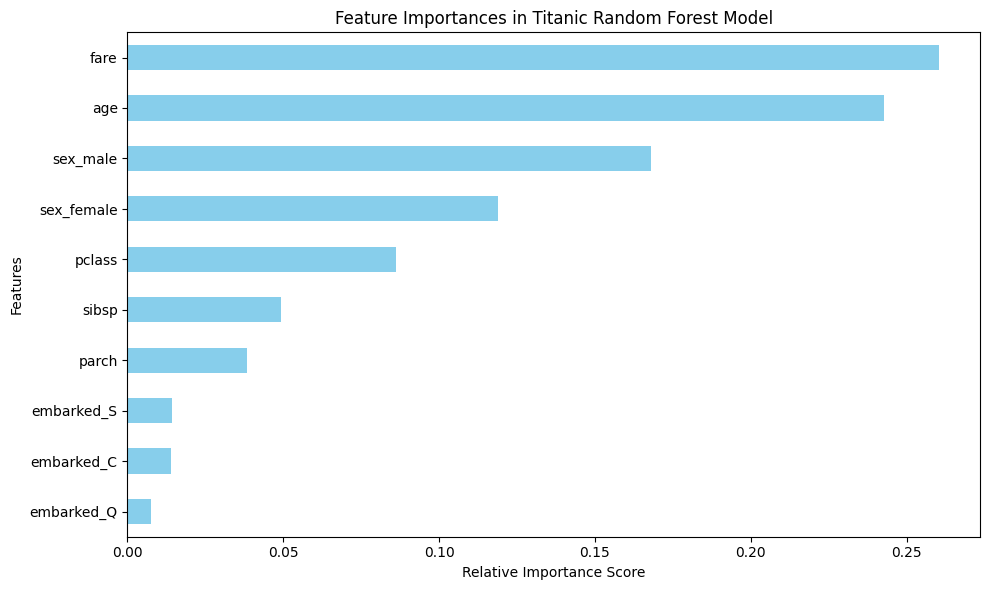

In [ ]:
#Cell 1: Check Feature Importance (See what the model learned)
import matplotlib.pyplot as plt

# 1. Get feature importances from the trained model
importances = model.feature_importances_
feature_names = X.columns

# 2. Create a dataframe for easy sorting
feat_importances = pd.Series(importances, index=feature_names).sort_values(ascending=True)

# 3. Plot the importances as a horizontal bar chart
plt.figure(figsize=(10, 6))
feat_importances.plot(kind='barh', color='skyblue')
plt.title('Feature Importances in Titanic Random Forest Model')
plt.xlabel('Relative Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


In [ ]:
#Save Your Preprocessed Data and Model
# Save the fully prepared dataframe to a CSV file in your Colab environment
df_encoded.to_csv('titanic_preprocessed_final.csv', index=False)
print("Dataset successfully saved as 'titanic_preprocessed_final.csv'!")


Dataset successfully saved as 'titanic_preprocessed_final.csv'!


Step 1: Feature Engineering (Creating Better Clues)
Instead of just giving the model raw variables, we can combine columns to build more meaningful clues. For example:
• family_size: Combining sibling/spouse and parent/children columns tells the model if someone was alone or with a large family.
• is_alone: A binary column showing if a passenger had no family on board.
• title: Extracting titles (like Mr., Mrs., Miss.) from names often captures social status better than class alone. (Since we are using Seaborn's dataset, we will engineer family_size and is_alone from sibsp and parch).
Paste this into a new cell to build and scale these features

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Reload a fresh copy of the dataset to keep it clean
df_advanced = sns.load_dataset('titanic')

# 1. Fill missing age values with the median
df_advanced['age'] = df_advanced['age'].fillna(df_advanced['age'].median())
df_advanced['embarked'] = df_advanced['embarked'].fillna(df_advanced['embarked'].mode()[0])

# 2. FEATURE ENGINEERING: Combine sibsp and parch to find family sizes
df_advanced['family_size'] = df_advanced['sibsp'] + df_advanced['parch'] + 1
df_advanced['is_alone'] = np.where(df_advanced['family_size'] == 1, 1, 0)

# 3. Categorical One-Hot Encoding
df_advanced = pd.get_dummies(df_advanced, columns=['sex', 'embarked'], drop_first=True)

# 4. Select features and drop non-numeric/redundant rows
drop_cols = ['survived', 'alive', 'who', 'adult_male', 'alone', 'class', 'deck', 'embark_town']
X_adv = df_advanced.drop(columns=[col for col in drop_cols if col in df_advanced.columns])
y_adv = df_advanced['survived']

# 5. Scale features (including our new family_size)
scaler_adv = StandardScaler()
scale_cols = ['age', 'fare', 'family_size']
X_adv[scale_cols] = scaler_adv.fit_transform(X_adv[scale_cols])

# Ensure all columns are purely numbers (convert booleans to 0/1)
X_adv = X_adv.astype(float)

# 6. Train-Test Split
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(X_adv, y_adv, test_size=0.2, random_state=42)

print("Advanced Features Created! Columns available:")
print(list(X_adv.columns))


Advanced Features Created! Columns available:
['pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone', 'sex_male', 'embarked_Q', 'embarked_S']


Step 2: Hyperparameter Tuning (Fine-Tuning the AI)
Instead of using the default settings, we use GridSearchCV to automatically test dozens of model settings (like tree depth and split criteria) to find the perfect configuration for our specific dataset.
Paste this code into the next cell:

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# 1. Define the grid of parameters we want to test
param_grid = {
    'n_estimators': [50, 100, 200],       # Number of trees in the forest
    'max_depth': [None, 5, 10, 15],       # How deep individual trees can grow
    'min_samples_split': [2, 5, 10],      # Minimum samples required to split a node
    'criterion': ['gini', 'entropy']      # Function to measure the quality of a split
}

# 2. Initialize a base Random Forest model
rf_base = RandomForestClassifier(random_state=42)

# 3. Setup the Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# 4. Search for the best settings using the training data
grid_search.fit(X_train_adv, y_train_adv)

# 5. Extract the absolute best model found
best_model = grid_search.best_estimator_

# 6. Predict and evaluate
y_pred_adv = best_model.predict(X_test_adv)

print("--- TUNING COMPLETE ---")
print(f"Best Parameters Found: {grid_search.best_params_}")
print(f"New Tuned Accuracy: {accuracy_score(y_test_adv, y_pred_adv):.2%}\n")
print(classification_report(y_test_adv, y_pred_adv))

NameError: name 'X_train_adv' is not defined

3. Handle Class Imbalance
In the Titanic dataset, more people perished than survived. When a dataset is uneven, models can get lazy and bias their guesses toward the majority outcome. You can force the model to treat both classes equally by setting the balance parameter inside your model initialization:

In [ ]:
# Tells the model to give higher mathematical weight to the minority class (survivors)
model = RandomForestClassifier(class_weight='balanced', random_state=42)
